# Avaliação final no teste oficial

Esta etapa apresenta a avaliação única do modelo, calibrador e threshold congelados no desenvolvimento. O teste oficial já foi consumido pelo script modular; as células deste notebook apenas carregam os artefatos persistidos para inspeção.

## 1. Contrato da avaliação

A avaliação não retorna ao processo de seleção. O contrato registra `test_used=true`, `evaluation_count=1` e `selection_contract_frozen=true`. A sobreposição conhecida de assinaturas entre treino e teste permanece uma limitação de independência.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from group_audit_plots import build_group_audit_svgs

evaluation_dir = ROOT / 'data' / 'processed' / 'final_evaluation'
contract = json.loads((evaluation_dir / 'final_test_contract.json').read_text(encoding='utf-8'))
global_metrics = pd.read_csv(evaluation_dir / 'final_test_metrics.csv')
group_metrics = pd.read_csv(evaluation_dir / 'final_test_group_metrics.csv')
sensitivity_metrics = pd.read_csv(evaluation_dir / 'final_test_sensitivity_metrics.csv')
sensitivity_group_metrics = pd.read_csv(evaluation_dir / 'final_test_sensitivity_group_metrics.csv')
display(pd.Series(contract, name='valor').to_frame())

,valor
protocol_version,final-test-evaluation-mvp-1
model,hist_gradient_boosting
threshold,0.31
tuned_model_params,"{'max_iter': 250, 'learning_rate': 0.05, 'max_..."
fit_rows,19537
calibration_rows,6512
selection_rows,6512
official_test_rows,16281
random_state,42
calibrator,sigmoid_platt_on_calibration_holdout


### Insights:
O modelo e o threshold foram avaliados uma única vez no `test_official`, sem reotimização posterior. As métricas abaixo representam a evidência final deste protocolo de portfolio, mas não autorizam generalização para produção devido às limitações do dataset e à sobreposição de assinaturas registrada no contrato.

## 2. Métricas globais no teste

A tabela mostra discriminação, qualidade probabilística e métricas de decisão no threshold congelado.

In [2]:
display(pd.concat([global_metrics.assign(analysis='primary_benchmark'), sensitivity_metrics.assign(analysis='sensitivity_excluding_overlap')], ignore_index=True).round(4))

,model,split,rows,prevalence,threshold,roc_auc,pr_auc,brier,precision,recall_tpr,f1,selection_rate,analysis
0,hist_gradient_boosting,test_official,16281,0.2362,0.31,0.9233,0.817,0.0903,0.6330,0.8138,0.7121,0.3037,primary_benchmark
1,hist_gradient_boosting,test_official_excluding_train_overlap,16255,0.2362,0.31,0.9232,0.817,0.0903,0.6326,0.8135,0.7118,0.3038,sensitivity_excluding_overlap


### Insights:
No teste oficial, o threshold congelado produz o compromisso observado entre precisão e recall. A interpretação deve permanecer descritiva: este é o desempenho no snapshot avaliado, não uma estimativa de desempenho futuro ou uma alegação de adequação operacional.

## 3. Auditoria de grupos no teste

As estimativas por sexo, raça e interseção usam intervalos de Wilson. Grupos com `low_support=true` exigem cautela adicional.

,model,threshold,audit_column,group,count,denominator,metric,estimate,ci_low,ci_high,low_support
0,hist_gradient_boosting,0.31,sex,Female,5421,5421,selection_rate,0.1341,0.1253,0.1434,False
1,hist_gradient_boosting,0.31,sex,Female,5421,590,tpr,0.7525,0.7162,0.7857,False
2,hist_gradient_boosting,0.31,sex,Female,5421,4831,fpr,0.0586,0.0523,0.0656,False
3,hist_gradient_boosting,0.31,sex,Female,5421,590,fnr,0.2475,0.2143,0.2838,False
4,hist_gradient_boosting,0.31,sex,Female,5421,727,ppv,0.6107,0.5748,0.6455,False
...,...,...,...,...,...,...,...,...,...,...,...
80,hist_gradient_boosting,0.31,sex_race,Male × White,9561,9561,selection_rate,0.4028,0.3930,0.4127,False
81,hist_gradient_boosting,0.31,sex_race,Male × White,9561,2976,tpr,0.8236,0.8095,0.8369,False
82,hist_gradient_boosting,0.31,sex_race,Male × White,9561,6585,fpr,0.2126,0.2029,0.2227,False
83,hist_gradient_boosting,0.31,sex_race,Male × White,9561,2976,fnr,0.1764,0.1631,0.1905,False


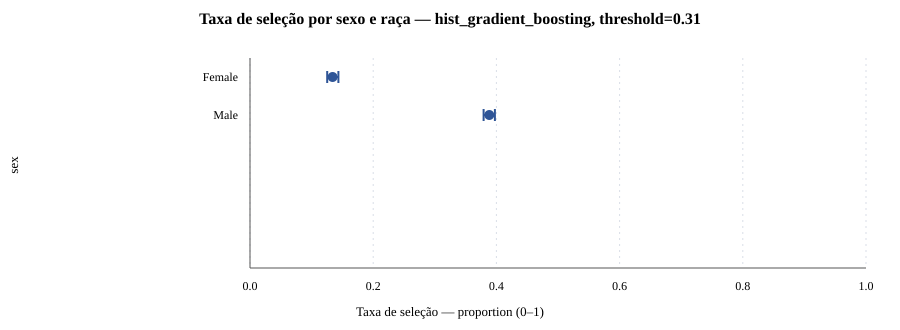

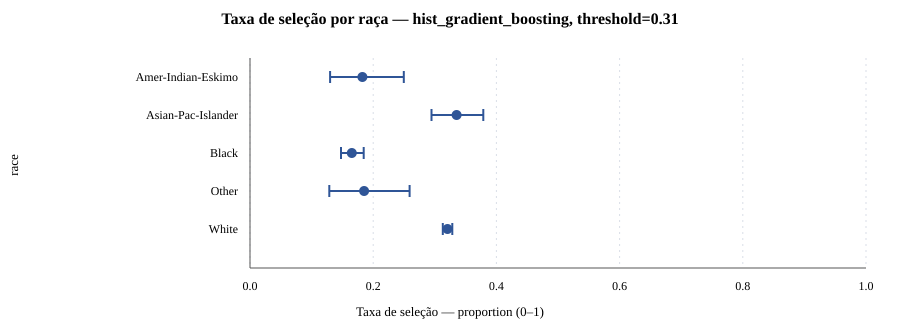

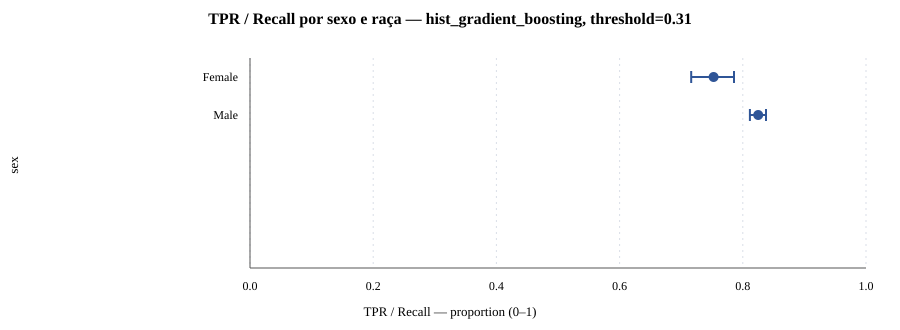

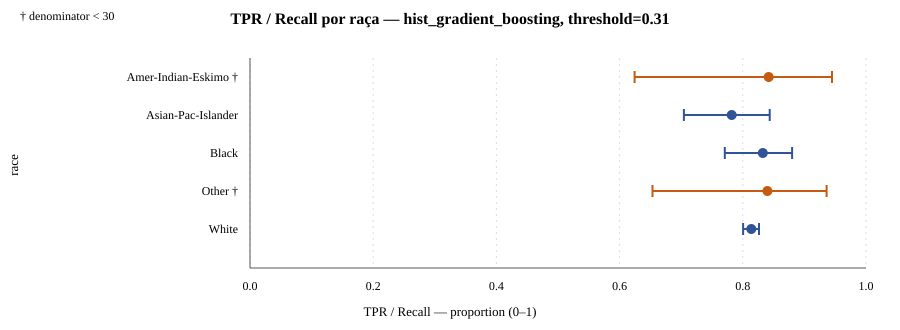

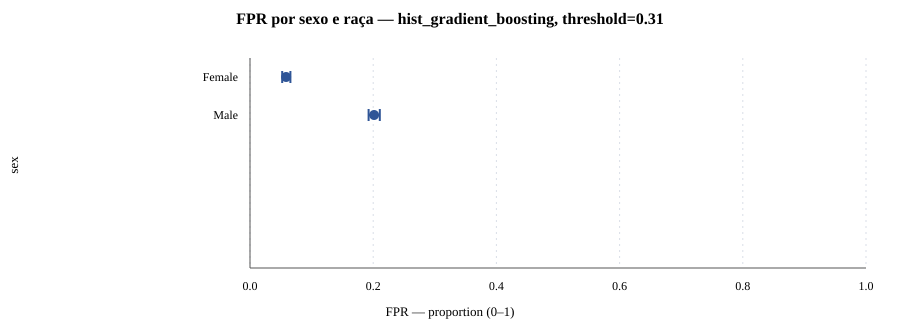

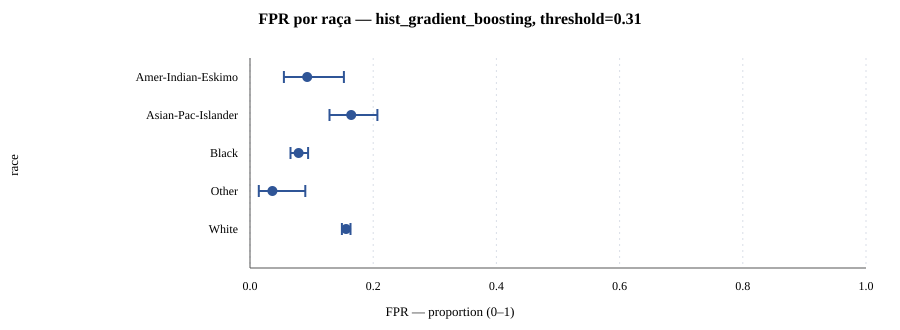

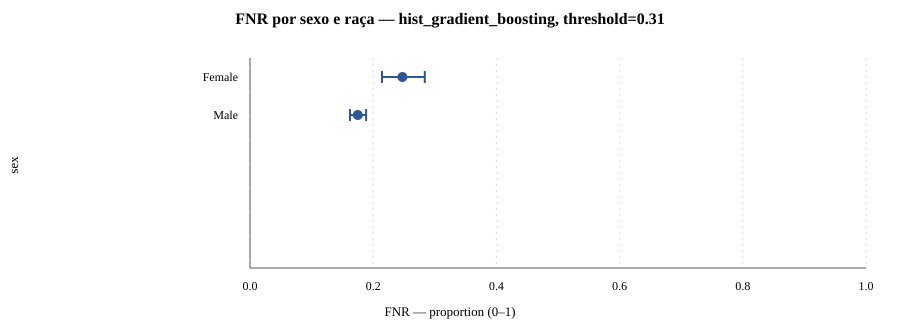

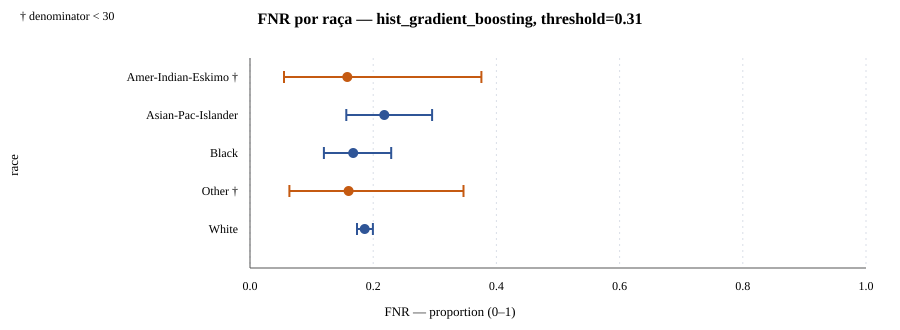

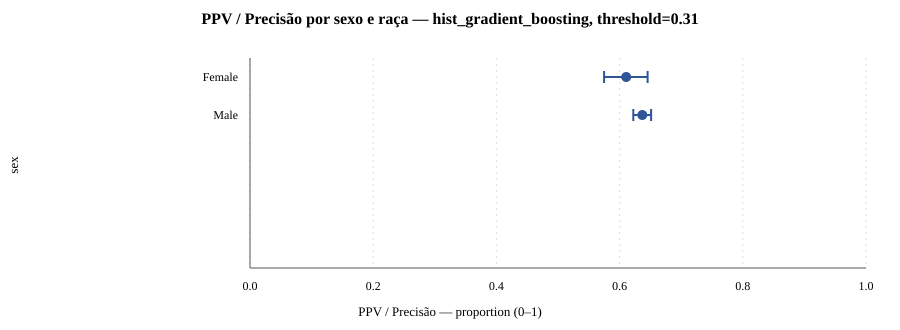

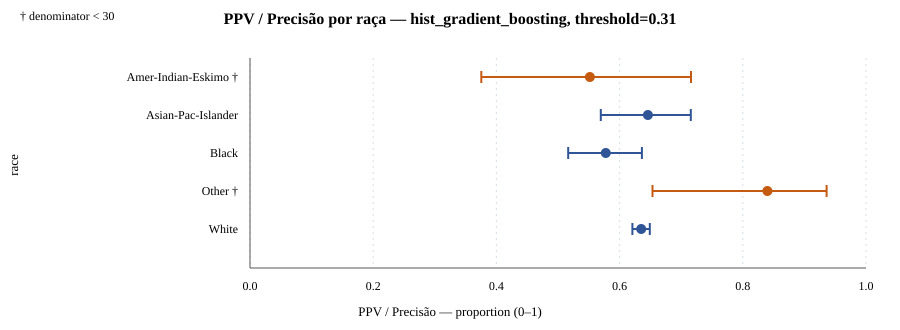

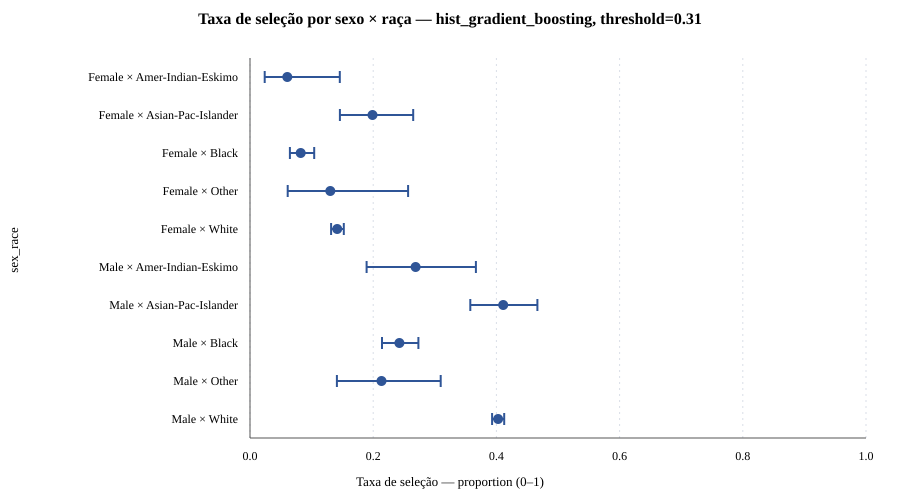

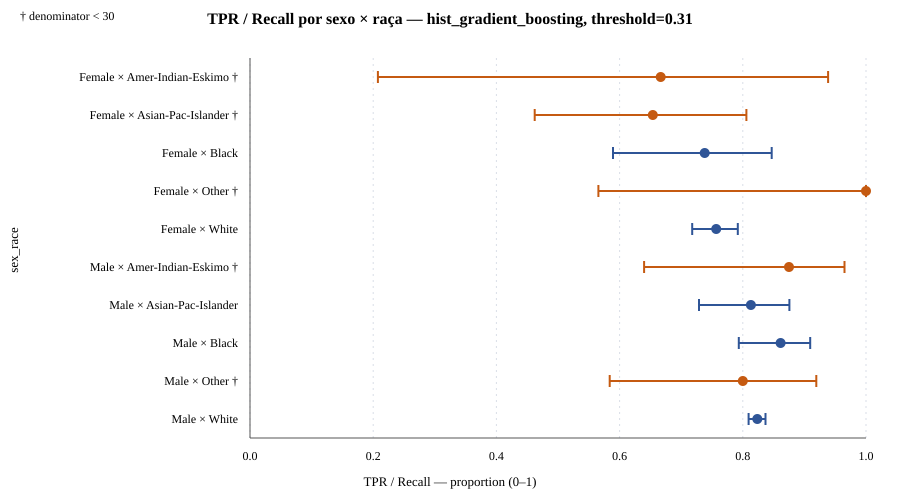

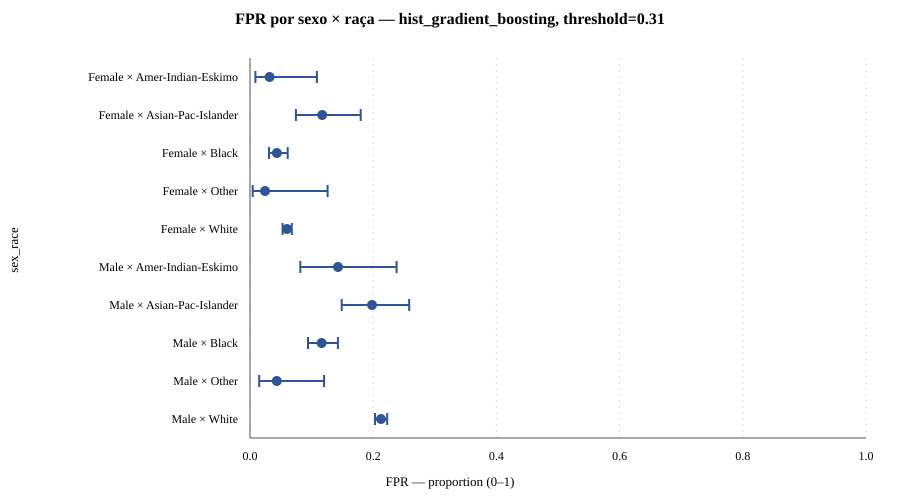

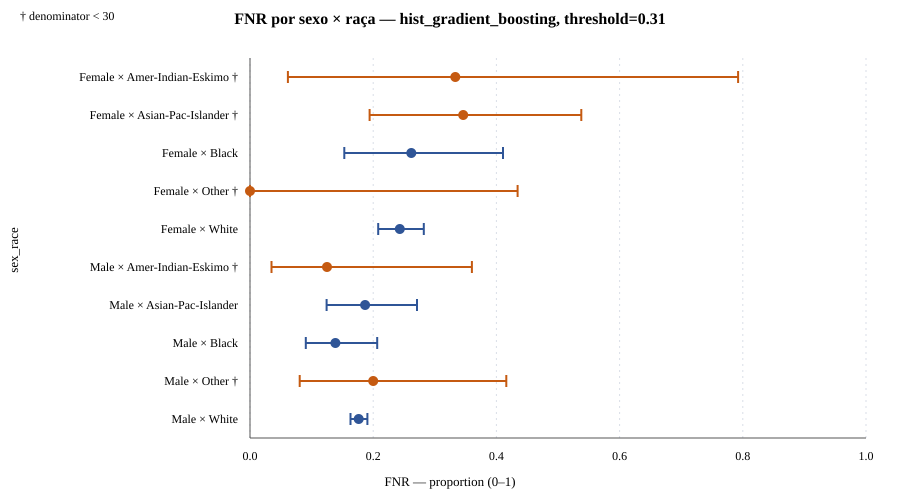

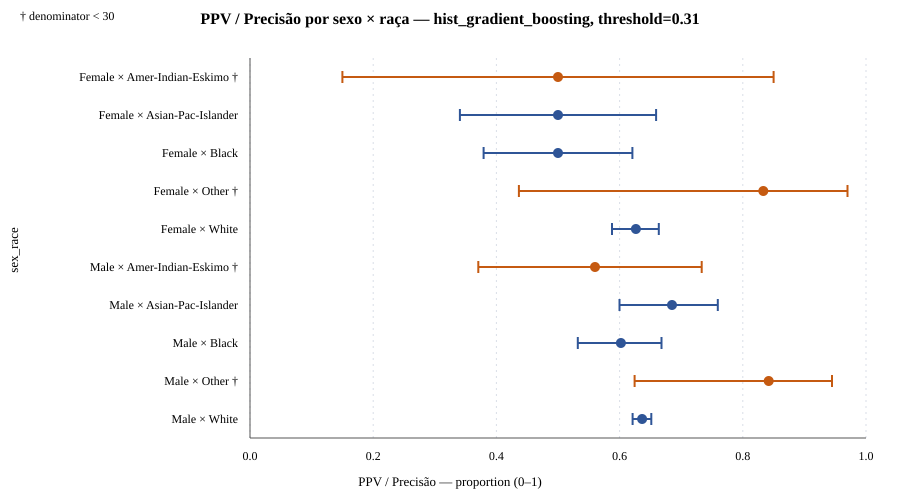

In [3]:
display(group_metrics.round(4))

labels = {
    'selection_rate': 'Taxa de seleção',
    'tpr': 'TPR / Recall',
    'fpr': 'FPR',
    'fnr': 'FNR',
    'ppv': 'PPV / Precisão',
}
model = contract['model']
threshold = contract['threshold']
group_svgs = build_group_audit_svgs(group_metrics, labels, model, threshold)
for svg in group_svgs['marginal'].values():
    display(SVG(svg))
for svg in group_svgs['intersection'].values():
    display(SVG(svg))

### Insights:
As diferenças entre grupos devem ser lidas junto com seus intervalos e denominadores. Elas descrevem o comportamento do modelo neste teste, mas não demonstram causalidade nem ausência de viés. O próximo artefato é o model card, que deve preservar essas limitações e o status `production_eligible=false`.